# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Pasion, Kyla Zarina
- _Student No._: 2024-09224
- _Section_: THR-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![Problem](./Figures/e11_figure1.png)
**Figure 1. Absolute error convergence across integration methods.** Log-log plots comparing the absolute error relative to `scipy.integrate.quad` against the number of divisions/points ($N$) for $y = \sqrt{9 - 4x^2}$, $y = -x^2 + 1$, and $y = \sqrt{x}\cos(x)$

![Problem](./Figures/e11_figure2.png)
**Figure 2. Monte Carlo bounded sampling distributions.** Scatter plots displaying sampled random points within the bounding box for each integrand, highlighting positive bounded points above the $x$-axis in blue, negative bounded points below the $x$-axis in red, and points outside the bounded region in gray. 

### Report discussion

Figure 1 shows how each method's error changes as the number of points ($N$) increases. For the parabola, both Simpson rules are exact because they integrate polynomials up to degree three without error, while the Trapezoidal rule error decreases steadily at an $\mathcal{O}(N^{-2})$ rate. For the square-root functions, Newton-Cotes methods converge more slowly because the derivative becomes unbounded at one endpoint, violating the smoothness assumptions required for their theoretical $\mathcal{O}(N^{-2})$ and $\mathcal{O}(N^{-4})$ error bounds. Monte Carlo has noisy, non-monotonic errors and converges more slowly, remaining less accurate than the Newton-Cotes methods for these one-dimensional integrals.

Figure 2 shows the Monte Carlo points sampled within the bounding rectangle. The semicircle lies entirely above the $x$-axis, so all enclosed points are blue, while the other functions have both blue and red regions. Blue points represent positive area and red points represent negative area; subtracting the red contributions from the blue gives the signed integral, while adding them gives the total area.

Monte Carlo integration estimates an integral by uniformly sampling points within a bounding rectangle. The fraction of points falling within the region bounded by the curve and the $x$-axis approximates the ratio of the enclosed area to the rectangle's area. Multiplying this fraction by the rectangle's area estimates the integral. By the Law of Large Numbers, this estimate approaches the true value as the number of samples increases, with a typical statistical error scaling of $\mathcal{O}(N^{-1/2})$.

Newton-Cotes methods are more suitable for smooth, low-dimensional integrands ($d=1$), where they provide deterministic results and converge significantly faster ($\mathcal{O}(N^{-2})$ to $\mathcal{O}(N^{-4})$). Monte Carlo methods are more advantageous for high-dimensional problems ($d \gg 1$), where grid-based deterministic methods become computationally expensive due to the curse of dimensionality, while Monte Carlo's $\mathcal{O}(N^{-1/2})$ convergence rate remains independent of dimension $d$.

### Other comments
- None


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import quad

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion:**

- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?

In [2]:
def trapezoidal(func, n, a, b):
    h = (b - a) / n  
    s = (func(a) + func(b)) / 2.0
    k = np.arange(1, n)
    s += np.sum(func(a + k * h))
    return h * s

def simpson13(func, n, a, b):
    h = (b - a) / n
    xs = np.linspace(a, b, n + 1)
    cs = np.ones(n + 1)
    cs[1:-1:2] = 4  # Odd indices
    cs[2:-2:2] = 2  # Even indices
    return (h / 3) * np.sum(cs * func(xs))

def simpson38(func, n, a, b):
    h = (b - a) / n
    xs = np.linspace(a, b, n + 1)
    cs = np.ones(n + 1) * 3
    cs[0] = 1
    cs[-1] = 1
    cs[3:-3:3] = 2  
    return (3 * h / 8) * np.sum(cs * func(xs)) # Internal boundary points

def montecarlo(func, n, a, b):
    xs = np.linspace(a, b, 1000)
    ys = func(xs)

    # Establish bounding box
    ymin = min(0, np.min(ys))
    ymax = max(0, np.max(ys))
    
    x_rand = np.random.uniform(a, b, n)
    y_rand = np.random.uniform(ymin, ymax, n)
    fx_rand = func(x_rand)
    
    blue_pts = (y_rand > 0) & (y_rand <= fx_rand)
    red_pts = (y_rand < 0) & (y_rand >= fx_rand)
    
    box_area = (b - a) * (ymax - ymin)
    
    signed_area = box_area * (np.sum(blue_pts) - np.sum(red_pts)) / n
    total_area = box_area * (np.sum(blue_pts) + np.sum(red_pts)) / n
    
    return signed_area, total_area, x_rand, y_rand, blue_pts, red_pts

In [3]:
# Initialize the bounds and N
a_bounds = [0, -2, 0]
b_bounds = [3/2, 2, np.pi]
N = 1200 

# Define the functions to be integrated
functions = [
    lambda x: np.sqrt(9 - 4 * x ** 2),
    lambda x: (-x**2 + 1),
    lambda x: (np.sqrt(x) * np.cos(x)),
]

func_names = [
    r"$y = \sqrt{9 - 4x^2}$",
    r"$y = -x^2 + 1$",
    r"$y = \sqrt{x}\cos(x)$"]

# N values must be multiples of 6 (even for Simpson 1/3, multiple of 3 for Simpson 3/8)
N_values = [6, 12, 60, 120, 300, 600, 1200]

In [4]:
# Compute numerical results
for i, (func, a, b) in enumerate(zip(functions, a_bounds, b_bounds)):
    print(f"\n Function {i+1} : Bounds [{a}, {b:.4f}]")
    
    scipy_integral, _ = quad(func, a, b)

    # Newton-Cotes integrals
    trap_int = trapezoidal(func, N, a, b)
    simp13_int = simpson13(func, N, a, b)
    simp38_int = simpson38(func, N, a, b)

    # Monte Carlo integration
    abs_func = lambda x: np.abs(func(x))
    trap_tot = trapezoidal(abs_func, N, a, b)
    
    mc_int, mc_tot, x_rand, y_rand, blue_pts, red_pts = montecarlo(func, 10000, a, b)

    print(f"Scipy Integral      : {scipy_integral:.6f}")
    print(f"Trapezoidal Integral: {trap_int:.6f} | Total Area: {trap_tot:.6f}")
    print(f"Simpson 1/3 Integral: {simp13_int:.6f}")
    print(f"Simpson 3/8 Integral: {simp38_int:.6f}")
    print(f"Monte Carlo Integral: {mc_int:.6f} | Total Area: {mc_tot:.6f}")


 Function 1 : Bounds [0, 1.5000]
Scipy Integral      : 3.534292
Trapezoidal Integral: 3.534260 | Total Area: 3.534260
Simpson 1/3 Integral: 3.534279
Simpson 3/8 Integral: 3.534277
Monte Carlo Integral: 3.518100 | Total Area: 3.518100

 Function 2 : Bounds [-2, 2.0000]
Scipy Integral      : -1.333333
Trapezoidal Integral: -1.333341 | Total Area: 4.000000
Simpson 1/3 Integral: -1.333333
Simpson 3/8 Integral: -1.333333
Monte Carlo Integral: -1.390399 | Total Area: 3.966396

 Function 3 : Bounds [0, 3.1416]
Scipy Integral      : -0.894831
Trapezoidal Integral: -0.894859 | Total Area: 2.302878
Simpson 1/3 Integral: -0.894842
Simpson 3/8 Integral: -0.894845
Monte Carlo Integral: -0.847970 | Total Area: 2.336089


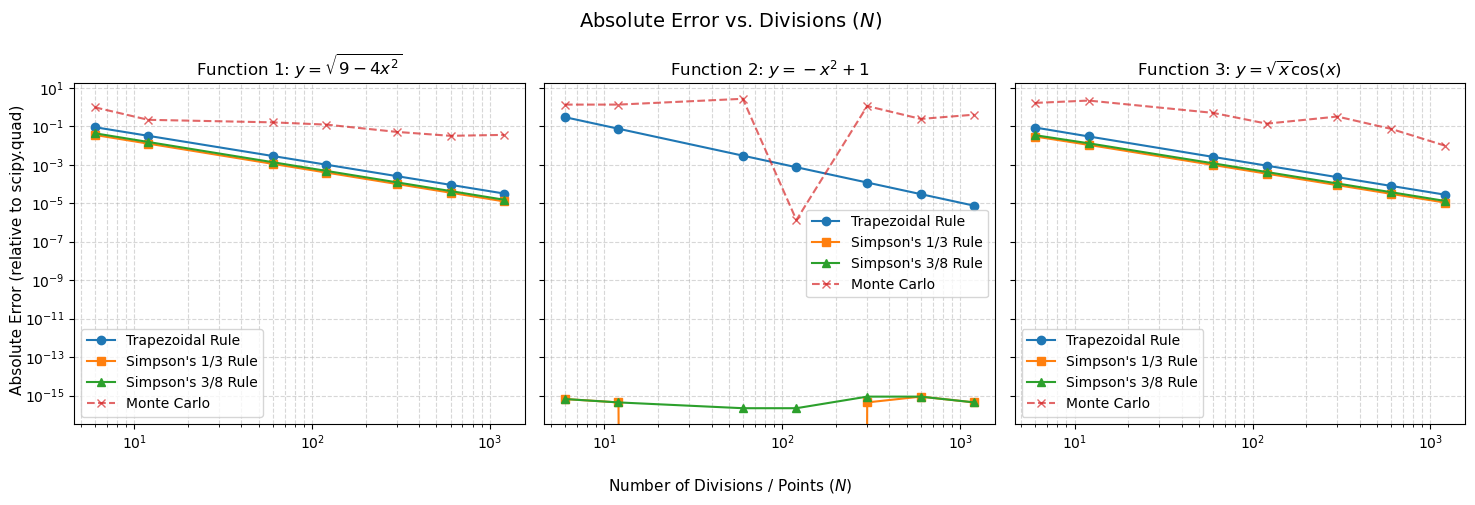

In [5]:
# Plot error figures 
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for i, (func, a, b, name) in enumerate(zip(functions, a_bounds, b_bounds, func_names)):
    scipy_integral, _ = quad(func, a, b)

    # Lists to store the errors
    trap_errors = []
    simp13_errors = []
    simp38_errors = []
    mc_errors = []
    
    for n in N_values:
        trap_errors.append(abs(trapezoidal(func, n, a, b) - scipy_integral))
        simp13_errors.append(abs(simpson13(func, n, a, b) - scipy_integral))
        simp38_errors.append(abs(simpson38(func, n, a, b) - scipy_integral))
        
        mc_int, _, _, _, _, _ = montecarlo(func, n, a, b)
        mc_errors.append(abs(mc_int - scipy_integral))

    # Absolute error vs. N
    ax = axes[i]
    ax.loglog(N_values, trap_errors, 'o-', label='Trapezoidal Rule')
    ax.loglog(N_values, simp13_errors, 's-', label="Simpson's 1/3 Rule")
    ax.loglog(N_values, simp38_errors, '^-', label="Simpson's 3/8 Rule")
    ax.loglog(N_values, mc_errors, 'x--', label='Monte Carlo', alpha=0.7)

    ax.set_title(f"Function {i+1}: {name}")
    ax.grid(True, which="both", ls="--", alpha=0.5)
    ax.legend()

fig.suptitle("Absolute Error vs. Divisions ($N$)", fontsize=14)
fig.supxlabel("Number of Divisions / Points ($N$)", fontsize=11)
fig.supylabel("Absolute Error (relative to scipy.quad)", fontsize=11)

plt.tight_layout()
plt.savefig("Figures/e11_figure1")
plt.show()

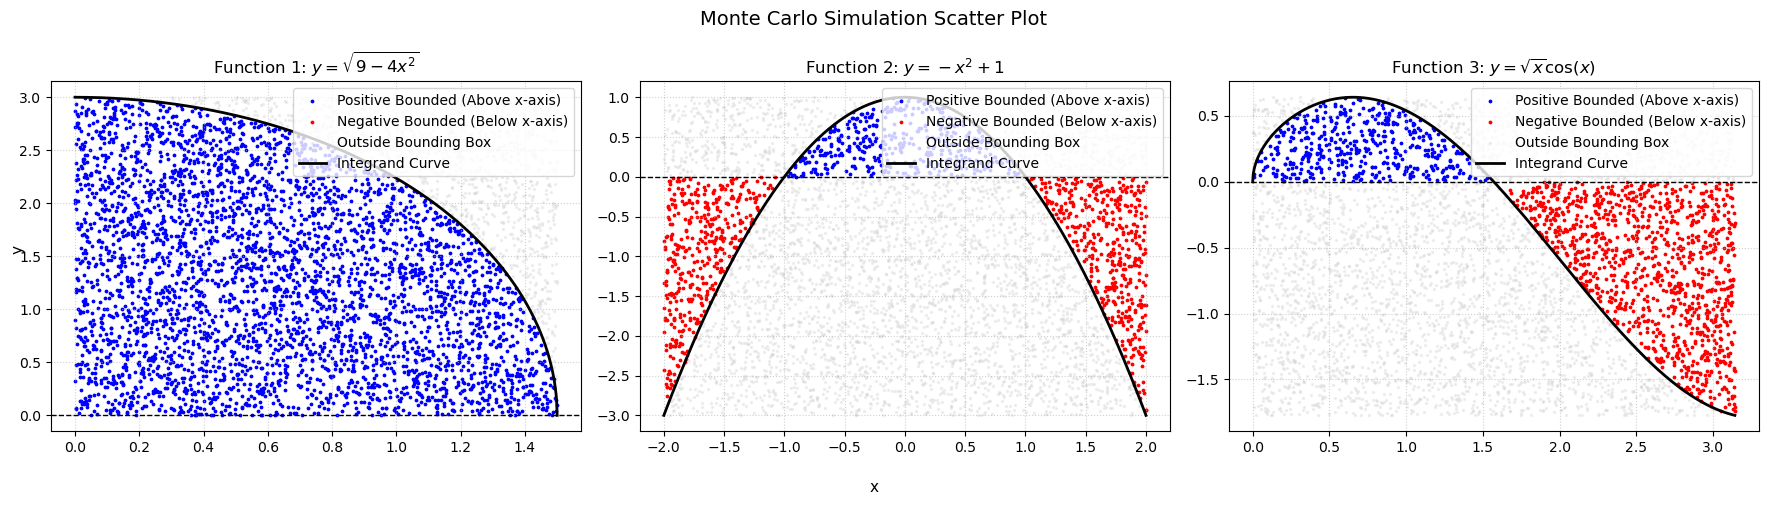

In [6]:
# Monte Carlo bounded points scatter plot 
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (func, a, b, name) in enumerate(zip(functions, a_bounds, b_bounds, func_names)):
    mc_int, mc_tot, x_rand, y_rand, blue_pts, red_pts = montecarlo(func, 5000, a, b)
    
    ax = axes[i]

    # Plot bounded points (blue = above x-axis, red = below x-axis)
    ax.scatter(x_rand[blue_pts], y_rand[blue_pts], color='blue', s=3, label='Positive Bounded (Above x-axis)')
    ax.scatter(x_rand[red_pts], y_rand[red_pts], color='red', s=3, label='Negative Bounded (Below x-axis)')

    # Plot points outside the bounded region in light gray to display the bounding box
    outside_pts = ~blue_pts & ~red_pts
    ax.scatter(x_rand[outside_pts], y_rand[outside_pts], color='lightgray', s=2, alpha=0.3, label='Outside Bounding Box')
    
    # Overlay actual curve and x-axis baseline
    xs = np.linspace(a, b, 1000)
    ax.plot(xs, func(xs), color='black', linewidth=2, label='Integrand Curve')
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    
    ax.set_title(f"Function {i+1}: {name}")
    ax.legend(loc='upper right')
    ax.grid(True, ls=":", alpha=0.6)

fig.suptitle("Monte Carlo Simulation Scatter Plot", fontsize=14)
fig.supxlabel("x", fontsize=11)
fig.supylabel("y", fontsize=11)

plt.tight_layout()
plt.savefig("Figures/e11_figure2")
plt.show()

### Problem code summary

This code evaluates numerical integration methods—Trapezoidal Rule, Simpson’s 1/3 Rule, Simpson’s 3/8 Rule, and Monte Carlo integration—against reference values from `scipy.integrate.quad` across three test functions. To optimize performance, the Newton-Cotes algorithms utilize vectorized NumPy array operations for fast coefficient weighting and evaluation. For the Monte Carlo visualization, it draws random points inside a box enclosing the curve and the x-axis, then uses boolean masks to keep only the points between them, coloring them blue above the axis and red below, so the signed integral and total area come directly from counting the points.